# PA27 — Data Quality & Exploratory Data Analysis

## 0. Setup

In [92]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from config.experiment import TARGET_COLUMN, RAW_WEATHER_VARIABLES
from src.preprocessing import (
    load_city_data, structural_quality_report, missing_values_report,
    invalid_values_report, unexpected_non_numeric_report,
    compare_city_timelines, compute_pooled_cold_threshold,
    add_cold_stress_target, get_warmup, get_evaluation_stream
)

FIG_DIR = ROOT / "outputs" / "eda_figures"
TAB_DIR = ROOT / "outputs" / "eda_tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

In [93]:
# Variables used
weather = list(RAW_WEATHER_VARIABLES)
cities = {name: load_city_data(name) for name in ["Porto", "Braganca"]}
cities = {name: add_cold_stress_target(df, threshold) for name, df in cities.items()}

In [94]:
# Treshold
threshold = compute_pooled_cold_threshold(list(cities.values()))
print(f"T3 pooled warm-up threshold (20th percentile): {threshold:.2f} °C")

T3 pooled warm-up threshold (20th percentile): 8.70 °C


In [95]:
# Time Period
for name, df in cities.items():
    print(name, len(df), df["timestamp_utc"].min(), df["timestamp_utc"].max())

Porto 87672 2016-01-01 00:00:00+00:00 2025-12-31 23:00:00+00:00
Braganca 87672 2016-01-01 00:00:00+00:00 2025-12-31 23:00:00+00:00


## 1. Data quality, missing values and invalid observations

### 1.1. General

In [96]:
quality_rows = []

for city, df in cities.items():
    report = structural_quality_report(df, city)
    quality_rows.append({
        k: v for k, v in report.items()
        if not isinstance(v, (dict, list))
    })

quality = pd.DataFrame(quality_rows)

display(quality)

quality.to_csv(TAB_DIR / "01_quality_summary.csv", index=False)

,city,rows,expected_rows,start,end,missing_values,duplicate_rows,duplicate_timestamps,missing_timestamps,unexpected_timestamps,infinite_values,chronological_order
0,Porto,87672,87672,2016-01-01T00:00:00+00:00,2025-12-31T23:00:00+00:00,0,0,0,0,0,0,True
1,Braganca,87672,87672,2016-01-01T00:00:00+00:00,2025-12-31T23:00:00+00:00,0,0,0,0,0,0,True


### By Variable

In [97]:
quality_variables = []

for city, df in cities.items():
    for variable in weather:
        quality_variables.append({
            "City": city,
            "Variable": variable,
            "Data type": str(df[variable].dtype),
            "Total observations": len(df),
            "Missing values": df[variable].isna().sum(),
            "Unique values": df[variable].nunique(),
            "Zero (%)": (df[variable] == 0).mean() * 100
        })

quality_variables = pd.DataFrame(quality_variables)

display(quality_variables)

,City,Variable,Data type,Total observations,Missing values,Unique values,Zero (%)
0,Porto,temperature_2m,float64,87672,0,360,0.000000
1,Porto,relative_humidity_2m,int64,87672,0,83,0.000000
2,Porto,precipitation,float64,87672,0,86,79.230541
3,Porto,wind_speed_10m,float64,87672,0,435,0.014828
4,Porto,dew_point_2m,float64,87672,0,272,0.033078
5,Porto,apparent_temperature,float64,87672,0,435,0.026234
6,Porto,vapour_pressure_deficit,float64,87672,0,387,0.117483
7,Porto,rain,float64,87672,0,86,79.230541
8,Porto,snowfall,float64,87672,0,1,100.000000
9,Porto,weather_code,int64,87672,0,10,31.476412


All variables contain 87672 observations per city, with no missing values. All variables are stored in numerical formats (`float64` or `int64`).

The only constant variable is `snowfall` in Porto, which has a single unique value.

Therefore, no missing-value imputation or data type conversion is required.

## 2. Descriptive statistics

This summarizes the main statistical characteristics of the weather variables, including their mean, median, standard deviation, and range, to compare weather conditions and variability between Porto and Bragança.

In [98]:
stats = pd.concat({name: df[weather].describe().T for name, df in cities.items()}, names=["city", "variable"])
display(stats.round(2))
stats.to_csv(TAB_DIR / "02_descriptive_statistics.csv")

count     mean      std     min  \
city     variable                                                        
Porto    temperature_2m              87672.0    15.96     5.41    0.40   
         relative_humidity_2m        87672.0    78.37    14.72   18.00   
         precipitation               87672.0     0.15     0.51    0.00   
         wind_speed_10m              87672.0    11.05     6.12    0.00   
         dew_point_2m                87672.0    11.85     4.44   -4.60   
         apparent_temperature        87672.0    15.26     6.84   -3.30   
         vapour_pressure_deficit     87672.0     0.47     0.48    0.00   
         rain                        87672.0     0.15     0.51    0.00   
         snowfall                    87672.0     0.00     0.00    0.00   
         weather_code                87672.0    12.18    21.23    0.00   
         pressure_msl                87672.0  1018.23     6.72  977.40   
         surface_pressure            87672.0  1007.82     6.61  967.30   
         cloud_cover                 87672.0    53.65    40.05    0.00   
         cloud_cover_low             87672.0    32.89    36.89    0.00   
         cloud_cover_mid             87672.0    19.51    30.33    0.00   
         cloud_cover_high            87672.0    29.96    38.78    0.00   
         wind_direction_10m          87672.0   196.31   109.69    1.00   
         shortwave_radiation         87672.0   185.82   266.16    0.00   
         sunshine_duration           87672.0  1507.47  1732.31    0.00   
         soil_temperature_0_to_7cm   87672.0    16.74     5.96    1.10   
         soil_temperature_7_to_28cm  87672.0    16.52     5.21    4.10   
         soil_moisture_0_to_7cm      87672.0     0.30     0.11    0.09   
         soil_moisture_7_to_28cm     87672.0     0.32     0.09    0.15   
Braganca temperature_2m              87672.0    13.55     7.69   -4.80   
         relative_humidity_2m        87672.0    69.04    21.43    9.00   
         precipitation               87672.0     0.10     0.39    0.00   
         wind_speed_10m              87672.0     9.44     5.37    0.00   
         dew_point_2m                87672.0     6.96     4.81  -15.70   
         apparent_temperature        87672.0    11.70     8.69   -8.60   
         vapour_pressure_deficit     87672.0     0.69     0.82    0.00   
         rain                        87672.0     0.10     0.39    0.00   
         snowfall                    87672.0     0.00     0.01    0.00   
         weather_code                87672.0     9.82    19.47    0.00   
         pressure_msl                87672.0  1018.48     7.02  977.60   
         surface_pressure            87672.0   939.41     6.31  900.70   
         cloud_cover                 87672.0    50.15    40.81    0.00   
         cloud_cover_low             87672.0    27.95    37.12    0.00   
         cloud_cover_mid             87672.0    20.24    30.29    0.00   
         cloud_cover_high            87672.0    30.55    38.74    0.00   
         wind_direction_10m          87672.0   180.21   105.05    1.00   
         shortwave_radiation         87672.0   186.08   268.63    0.00   
         sunshine_duration           87672.0  1480.33  1726.26    0.00   
         soil_temperature_0_to_7cm   87672.0    14.43     7.72   -2.30   
         soil_temperature_7_to_28cm  87672.0    14.29     6.82    0.90   
         soil_moisture_0_to_7cm      87672.0     0.29     0.10    0.12   
         soil_moisture_7_to_28cm     87672.0     0.28     0.10    0.13   

                                         25%      50%      75%      max  
city     variable                                                        
Porto    temperature_2m                12.20    15.70    19.50    37.00  
         relative_humidity_2m          69.00    82.00    90.00   100.00  
         precipitation                  0.00     0.00     0.00    14.00  
         wind_speed_10m                 6.50    10.10    14.40    50.60  
         dew_point_2m                   8.

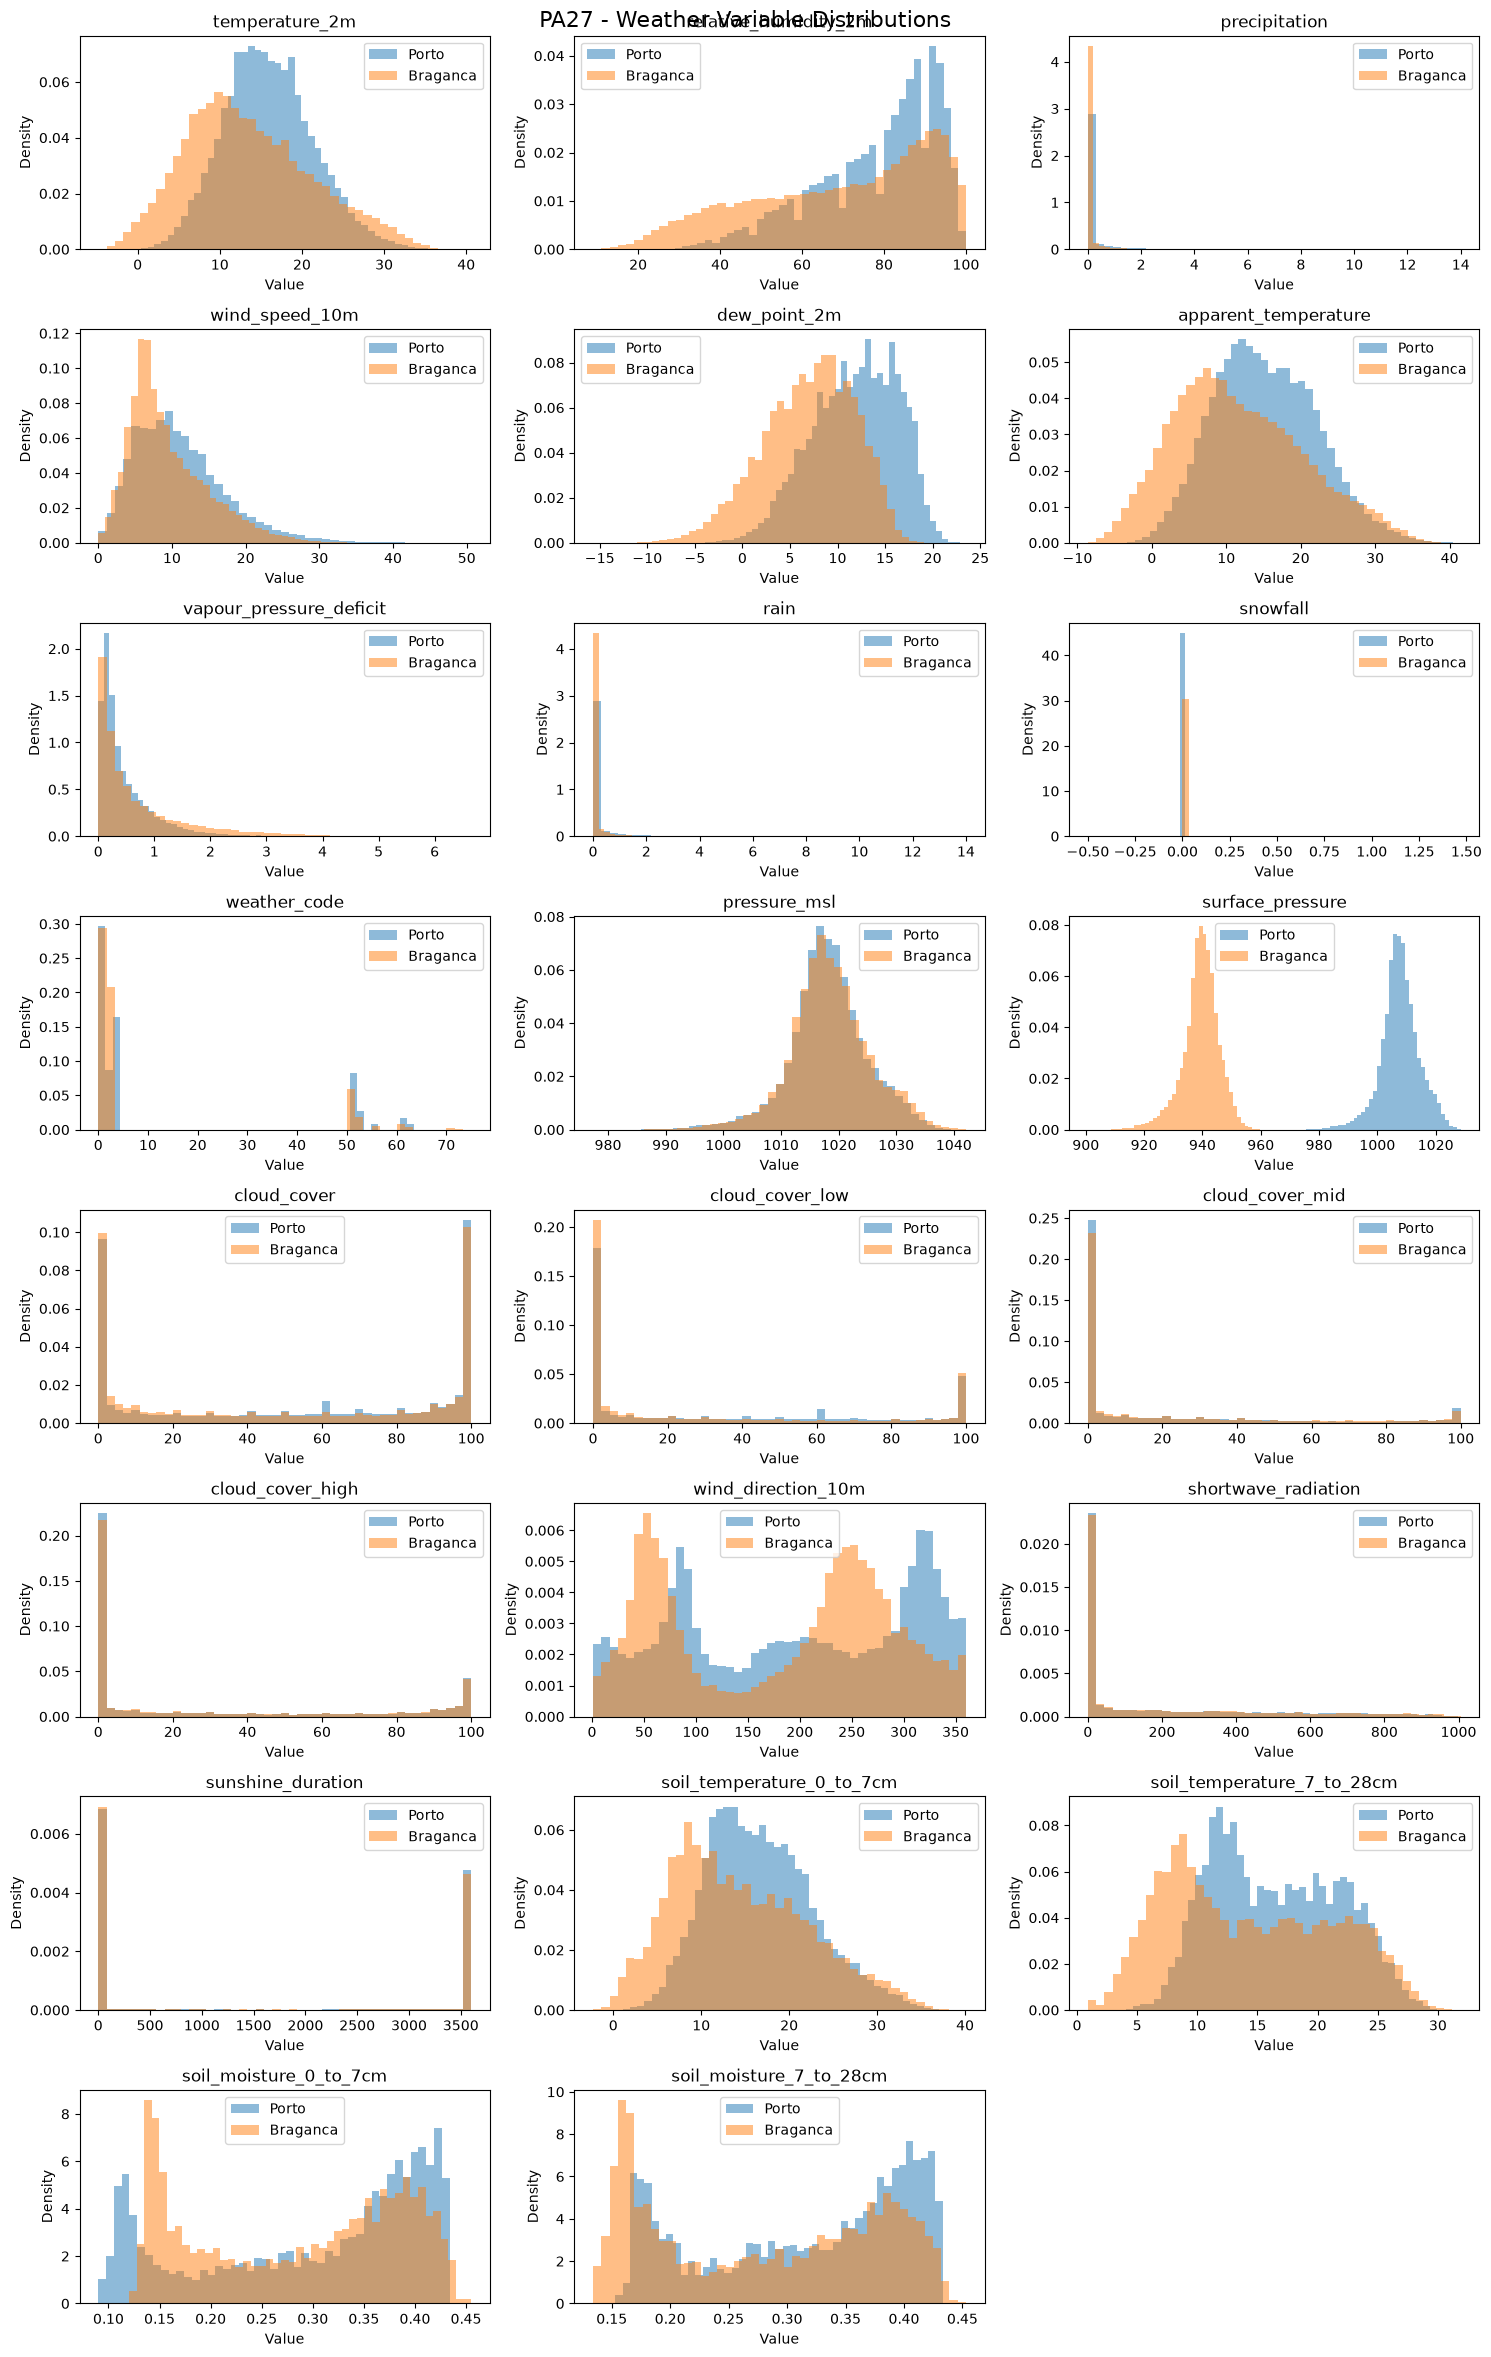

In [99]:
n_cols = 3
n_rows = math.ceil(len(weather) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, n_rows * 3)
)

for ax, var in zip(axes.flat, weather):

    for city, df in cities.items():
        ax.hist(
            df[var].dropna(),
            bins=45,
            alpha=0.5,
            density=True,
            label=city
        )

    ax.set_title(var)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.legend()

# Remove empty subplots
for ax in axes.flat[len(weather):]:
    ax.set_visible(False)

fig.suptitle("PA27 - Weather Variable Distributions", fontsize=16)
fig.tight_layout()

fig.savefig(
    FIG_DIR / "02_weather_distributions.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


## 3. Correlations

### 3.1. Correlation Between Weather Variables

We used Pearson correlation coefficients to identify relationships between meteorological variables and detect potential multicollinearity, which helps us examine redundancy and support feature selection.


Correlation Matrix - Porto


,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,dew_point_2m,apparent_temperature,vapour_pressure_deficit,rain,snowfall,weather_code,...,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_direction_10m,shortwave_radiation,sunshine_duration,soil_temperature_0_to_7cm,soil_temperature_7_to_28cm,soil_moisture_0_to_7cm,soil_moisture_7_to_28cm
temperature_2m,1.00,-0.53,-0.09,-0.00,0.78,0.98,0.75,-0.09,NaN,-0.14,...,-0.23,-0.20,-0.10,0.29,0.57,0.45,0.96,0.84,-0.66,-0.64
relative_humidity_2m,-0.53,1.00,0.22,-0.13,0.11,-0.42,-0.89,0.22,NaN,0.34,...,0.55,0.27,0.17,-0.04,-0.65,-0.58,-0.46,-0.21,0.35,0.28
precipitation,-0.09,0.22,1.00,0.38,0.05,-0.12,-0.18,1.00,NaN,0.63,...,0.31,0.48,0.21,0.05,-0.10,-0.13,-0.10,-0.12,0.27,0.22
wind_speed_10m,-0.00,-0.13,0.38,1.00,-0.09,-0.15,0.07,0.38,NaN,0.41,...,0.13,0.34,0.10,0.15,0.12,0.11,-0.01,-0.13,0.21,0.20
dew_point_2m,0.78,0.11,0.05,-0.09,1.00,0.84,0.20,0.05,NaN,0.07,...,0.11,-0.04,0.01,0.32,0.19,0.12,0.79,0.83,-0.52,-0.55
apparent_temperature,0.98,-0.42,-0.12,-0.15,0.84,1.00,0.67,-0.12,NaN,-0.17,...,-0.20,-0.22,-0.10,0.28,0.52,0.39,0.96,0.86,-0.67,-0.66
vapour_pressure_deficit,0.75,-0.89,-0.18,0.07,0.20,0.67,1.00,-0.18,NaN,-0.29,...,-0.45,-0.26,-0.16,0.11,0.69,0.54,0.69,0.45,-0.49,-0.43
rain,-0.09,0.22,1.00,0.38,0.05,-0.12,-0.18,1.00,NaN,0.63,...,0.31,0.48,0.21,0.05,-0.10,-0.13,-0.10,-0.12,0.27,0.22
snowfall,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather_code,-0.14,0.34,0.63,0.41,0.07,-0.17,-0.29,0.63,NaN,1.00,...,0.48,0.63,0.26,0.11,-0.14,-0.16,-0.16,-0.19,0.40,0.32


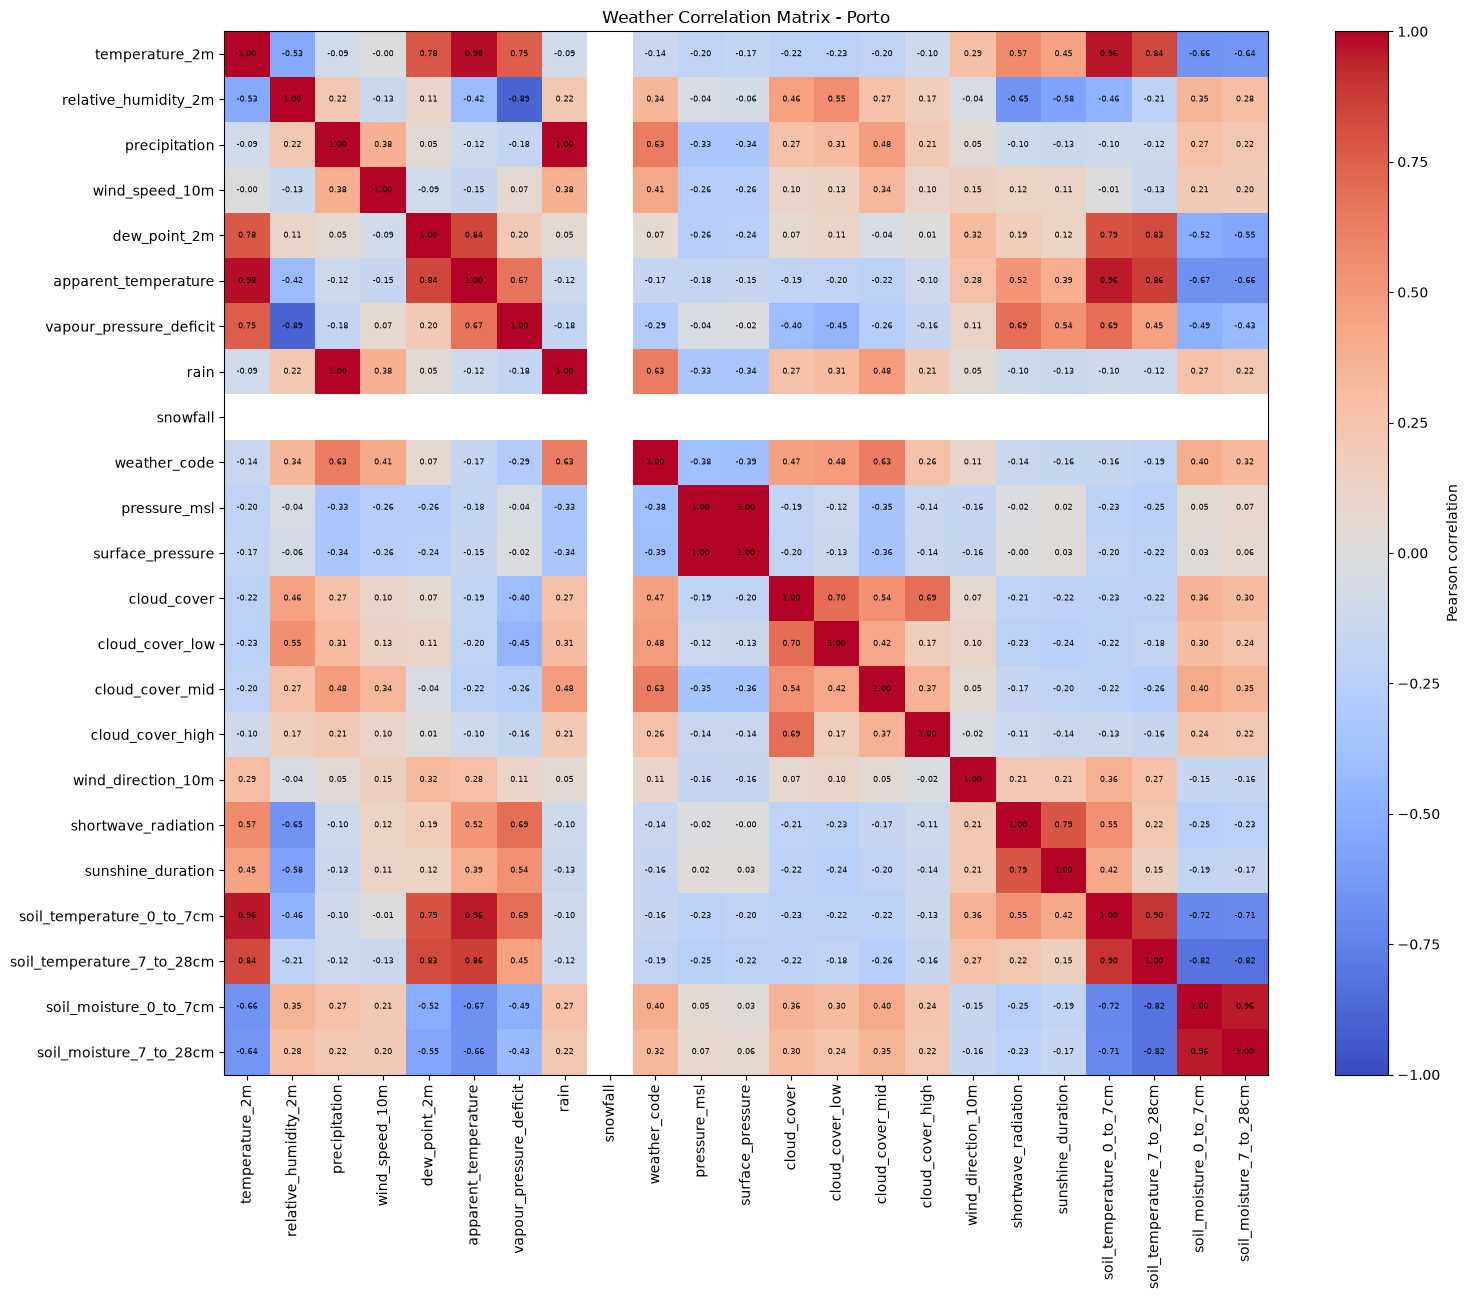


Correlation Matrix - Braganca


,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,dew_point_2m,apparent_temperature,vapour_pressure_deficit,rain,snowfall,weather_code,...,cloud_cover_low,cloud_cover_mid,cloud_cover_high,wind_direction_10m,shortwave_radiation,sunshine_duration,soil_temperature_0_to_7cm,soil_temperature_7_to_28cm,soil_moisture_0_to_7cm,soil_moisture_7_to_28cm
temperature_2m,1.00,-0.74,-0.08,0.04,0.64,0.99,0.87,-0.08,-0.06,-0.15,...,-0.33,-0.17,-0.08,0.13,0.60,0.50,0.97,0.84,-0.66,-0.65
relative_humidity_2m,-0.74,1.00,0.24,-0.04,0.01,-0.68,-0.88,0.24,0.05,0.36,...,0.55,0.30,0.19,0.02,-0.65,-0.60,-0.70,-0.53,0.63,0.56
precipitation,-0.08,0.24,1.00,0.29,0.12,-0.08,-0.16,1.00,0.12,0.64,...,0.33,0.44,0.21,0.05,-0.08,-0.11,-0.09,-0.10,0.26,0.19
wind_speed_10m,0.04,-0.04,0.29,1.00,0.01,-0.06,0.02,0.29,0.05,0.38,...,0.32,0.29,0.05,0.14,0.12,0.10,0.03,-0.05,0.15,0.12
dew_point_2m,0.64,0.01,0.12,0.01,1.00,0.70,0.23,0.13,-0.05,0.15,...,0.09,0.07,0.08,0.19,0.15,0.10,0.65,0.67,-0.30,-0.36
apparent_temperature,0.99,-0.68,-0.08,-0.06,0.70,1.00,0.83,-0.08,-0.06,-0.15,...,-0.32,-0.17,-0.08,0.12,0.59,0.47,0.97,0.85,-0.66,-0.65
vapour_pressure_deficit,0.87,-0.88,-0.16,0.02,0.23,0.83,1.00,-0.16,-0.03,-0.26,...,-0.42,-0.24,-0.15,0.07,0.67,0.54,0.84,0.65,-0.62,-0.56
rain,-0.08,0.24,1.00,0.29,0.13,-0.08,-0.16,1.00,0.07,0.63,...,0.33,0.44,0.21,0.05,-0.08,-0.11,-0.08,-0.10,0.26,0.18
snowfall,-0.06,0.05,0.12,0.05,-0.05,-0.06,-0.03,0.07,1.00,0.14,...,0.07,0.09,0.03,0.00,-0.02,-0.03,-0.05,-0.05,0.05,0.04
weather_code,-0.15,0.36,0.64,0.38,0.15,-0.15,-0.26,0.63,0.14,1.00,...,0.53,0.60,0.28,0.10,-0.10,-0.13,-0.16,-0.19,0.39,0.30


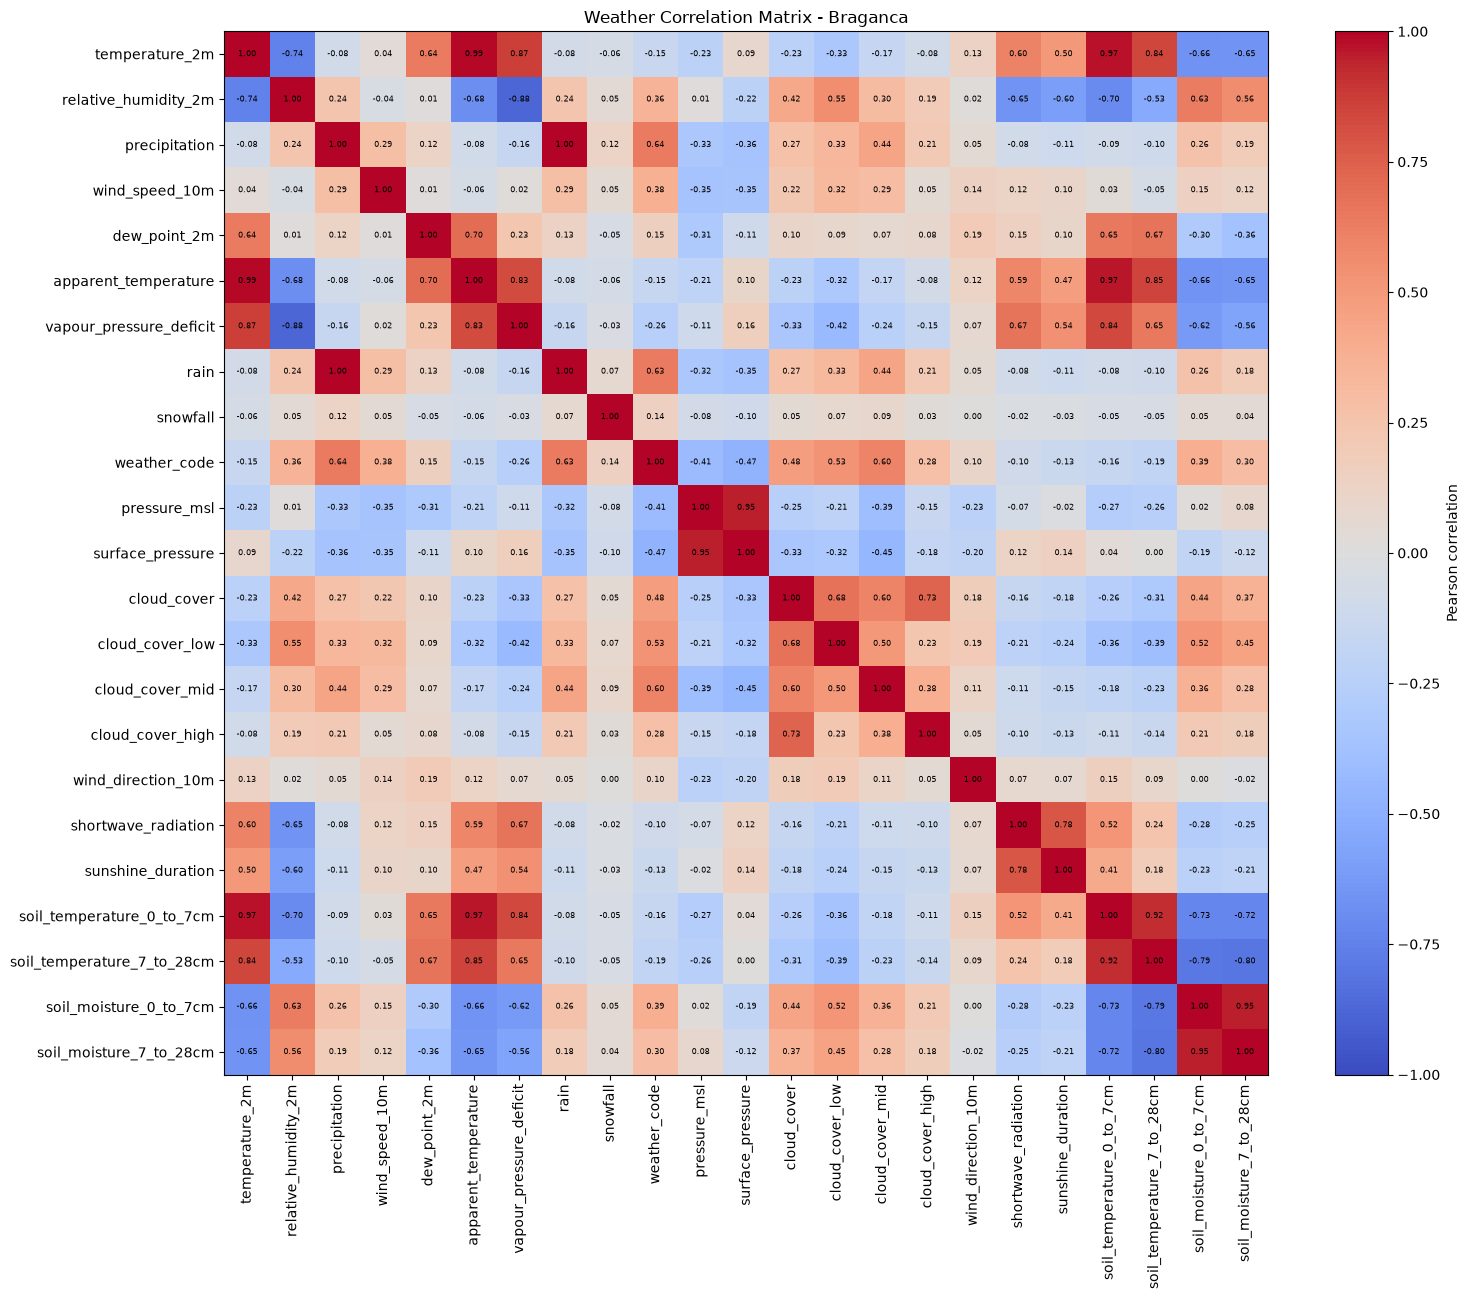

In [100]:
for city, df in cities.items():

    # Calculate Pearson correlation
    corr = df[weather].corr(method="pearson")

    # Display correlation table
    print(f"\nCorrelation Matrix - {city}")
    display(corr.round(2))

    # Create heatmap
    fig, ax = plt.subplots(figsize=(16, 13))

    im = ax.imshow(
        corr,
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    # Variable names
    ax.set_xticks(range(len(weather)))
    ax.set_yticks(range(len(weather)))

    ax.set_xticklabels(weather, rotation=90)
    ax.set_yticklabels(weather)

    # Correlation values
    for i in range(len(weather)):
        for j in range(len(weather)):
            if not np.isnan(corr.iloc[i, j]):
                ax.text(
                    j, i,
                    f"{corr.iloc[i, j]:.2f}",
                    ha="center",
                    va="center",
                    fontsize=6
                )

    fig.colorbar(im, ax=ax, label="Pearson correlation")

    ax.set_title(f"Weather Correlation Matrix - {city}")

    plt.tight_layout()

    # Save heatmap
    fig.savefig(
        FIG_DIR / f"correlation_{city}.png",
        dpi=150,
        bbox_inches="tight"
    )

    # Save correlation table
    corr.round(2).to_csv(
        TAB_DIR / f"correlation_{city}.csv"
    )

    plt.show()
    plt.close(fig)

**Strong positive correlations:**
- `temperature_2m` and `apparent_temperature`: Porto (r = 0.98); Bragança (r = 0.99).
- `temperature_2m` and `soil_temperature_0_to_7cm`: Porto (r = 0.96); Bragança (r = 0.97).
- `precipitation` and `rain`: Porto (r = 1.00); Bragança (r = 1.00).
- `pressure_msl` and `surface_pressure`: Porto (r = 1.00); Bragança (r = 0.95).
- `soil_moisture_0_to_7cm` and `soil_moisture_7_to_28cm`: Porto (r = 0.96); Bragança (r = 0.95).

**Strong negative correlations:**
- `relative_humidity_2m` and `vapour_pressure_deficit`: Porto (r = -0.89); Bragança (r = -0.88).
- `temperature_2m` and `relative_humidity_2m`: Porto (r = -0.53); Bragança (r = -0.74).

For each pair of highly correlated variables, we examined scatterplots to visually assess whether the relationship was approximately linear or exhibited non-linear patterns.

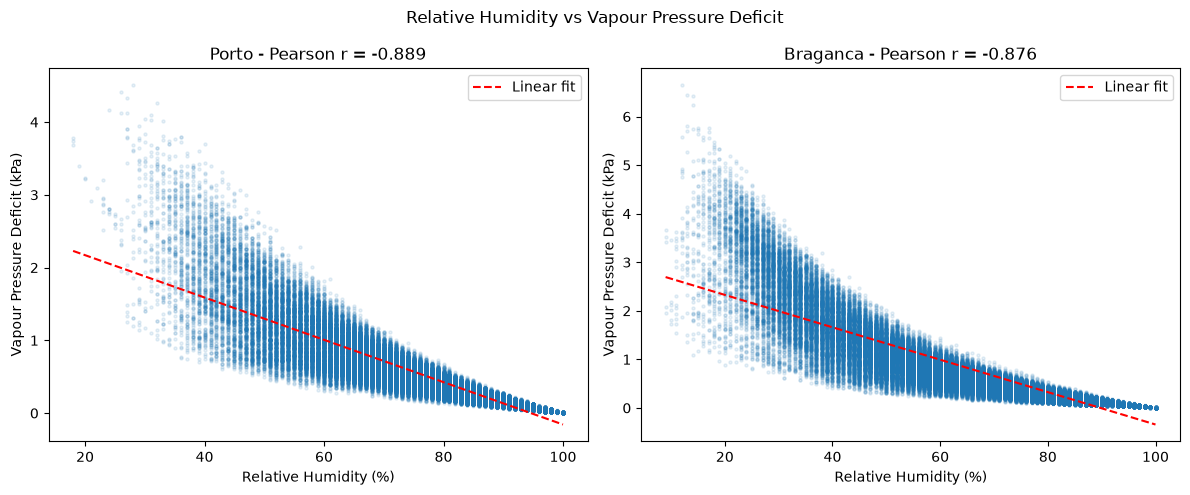

In [101]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (city, df) in zip(axes, cities.items()):

    x = df["relative_humidity_2m"]
    y = df["vapour_pressure_deficit"]

    # Scatterplot
    ax.scatter(x, y, alpha=0.1, s=5)

    # Linear regression line
    slope, intercept = np.polyfit(x, y, 1)

    ax.plot(
        np.sort(x),
        slope * np.sort(x) + intercept,
        "r--",
        label="Linear fit"
    )

    # Pearson correlation
    correlation = x.corr(y)

    ax.set_title(f"{city} - Pearson r = {correlation:.3f}")
    ax.set_xlabel("Relative Humidity (%)")
    ax.set_ylabel("Vapour Pressure Deficit (kPa)")
    ax.legend()

plt.suptitle("Relative Humidity vs Vapour Pressure Deficit")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "humidity_vs_vpd.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


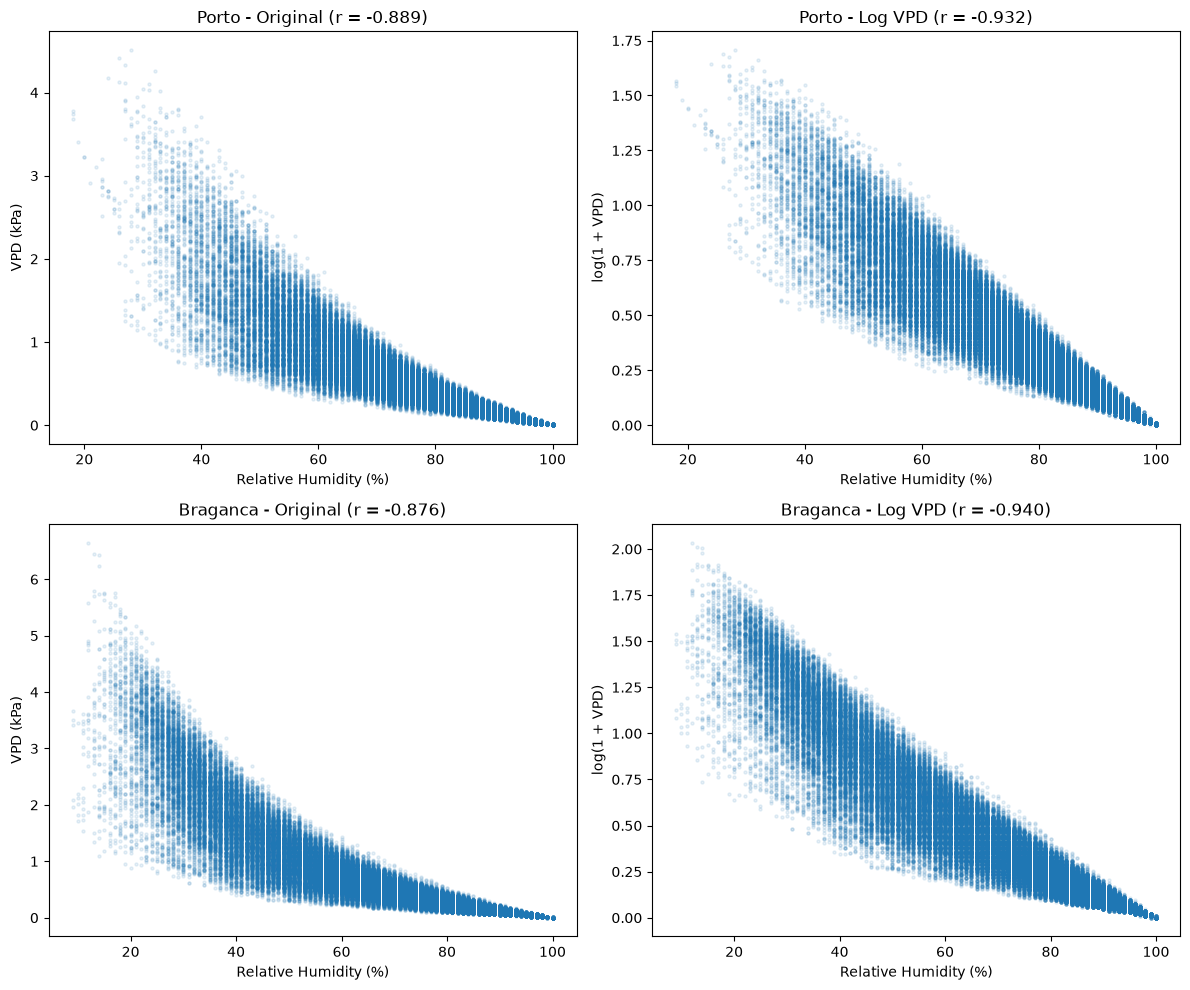

In [102]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, (city, df) in enumerate(cities.items()):

    x = df["relative_humidity_2m"]
    y = df["vapour_pressure_deficit"]

    # Original relationship
    axes[i, 0].scatter(x, y, alpha=0.1, s=5)
    axes[i, 0].set_title(
        f"{city} - Original (r = {x.corr(y):.3f})"
    )
    axes[i, 0].set_xlabel("Relative Humidity (%)")
    axes[i, 0].set_ylabel("VPD (kPa)")

    # Log-transformed VPD
    y_log = np.log1p(y)

    axes[i, 1].scatter(x, y_log, alpha=0.1, s=5)
    axes[i, 1].set_title(
        f"{city} - Log VPD (r = {x.corr(y_log):.3f})"
    )
    axes[i, 1].set_xlabel("Relative Humidity (%)")
    axes[i, 1].set_ylabel("log(1 + VPD)")

plt.tight_layout()
plt.show()


**Note:** VPD is `vapour_pressure_deficit`.

Initially, `relative_humidity_2m` and `vapour_pressure_deficit` showed a strong negative correlation, but the scatterplots revealed a nonlinear relationship and uneven dispersion. A log transformation was applied to VPD to investigate the relationship, improving the absolute Pearson correlation from 0.889 to 0.932 in Porto and from 0.876 to 0.940 in Bragança, although some nonlinearity remained. Therefore, both variables will be retained for now.

### 3.2. Correlation with the Target

Pearson correlation coefficients were calculated between lagged meteorological variables and the Cold Stress target (T3), using only the warm-up period to avoid future information leakage. This analysis assesses the strength and direction of linear relationships and supports feature selection before the evaluation phase.

In [103]:
for city, df in cities.items():

    warmup = get_warmup(df).copy()

    # Previous-hour weather variables
    X = warmup[weather].shift(1)
    X = X.dropna()

    # Cold Stress at the current hour
    X[TARGET_COLUMN] = warmup[TARGET_COLUMN]

    correlations = (
        X.corr()[TARGET_COLUMN]
        .drop(TARGET_COLUMN)
        .sort_values(key=abs, ascending=False)
    )

    print(f"\nLagged feature correlations - {city}")

    display(correlations.to_frame("Correlation"))


Lagged feature correlations - Porto


,Correlation
temperature_2m,-0.526858
dew_point_2m,-0.514877
apparent_temperature,-0.513478
soil_temperature_0_to_7cm,-0.471361
soil_temperature_7_to_28cm,-0.411491
soil_moisture_7_to_28cm,0.244190
sunshine_duration,-0.241302
soil_moisture_0_to_7cm,0.241206
vapour_pressure_deficit,-0.233456
shortwave_radiation,-0.216109



Lagged feature correlations - Braganca


,Correlation
apparent_temperature,-0.718955
temperature_2m,-0.717360
soil_temperature_0_to_7cm,-0.690019
soil_temperature_7_to_28cm,-0.649492
dew_point_2m,-0.584421
soil_moisture_7_to_28cm,0.519240
soil_moisture_0_to_7cm,0.506335
relative_humidity_2m,0.494827
vapour_pressure_deficit,-0.466042
shortwave_radiation,-0.367525


**Weak correlations with Cold Stress in both locations:**
- `precipitation`: Porto (r = -0.037665); Bragança (r = 0.031926).
- `rain`: Porto (r = -0.037665); Bragança (r = 0.028953).
- `wind_speed_10m`: Porto (r = -0.026517); Bragança (r = -0.040778).
- `cloud_cover_high`: Porto (r = -0.057942); Bragança (r = 0.025932).
- `weather_code`: Porto (r = -0.046564); Bragança (r = 0.077282).
- `snowfall`: Bragança (r = 0.089324); Porto (r = NaN).

**Weak correlations with Cold Stress in one location:**
- `cloud_cover_low`: Porto (r = -0.035657).
- `cloud_cover_mid`: Porto (r = -0.029556).
- `cloud_cover`: Porto (r = -0.059787).
- `wind_direction_10m`: Bragança (r = -0.083577).
- `surface_pressure`: Bragança (r = -0.012005).

### 3.3. Feature Selection based on Correlation

**Correlation-based Feature Removal:**
- Correlation with the target: |r| < 0.10
- Multicolinearity: |r| > 0.85

**Variables to Remove in Porto:**
- `apparent_temperature`: high correlation with `temperature_2m` (`temperature_2m` has a higher absolute correlation with the target).
- `relative_humidity_2m`: high negative correlation with `vapour_pressure_deficit` (`vapour_pressure_deficit` has a higher absolute correlation with the target).
- `rain` and `precipitation`: perfect correlation with each other and both have low correlation with the target.
- `surface_pressure`: high correlation with `pressure_msl` (`pressure_msl` has a higher absolute correlation with the target).
- `snowfall`: undefined correlation due to zero variance.
- `cloud_cover_high`, `cloud_cover_mid`, `cloud_cover_low`: low correlation with the target.
- `cloud_cover`: low correlation with the target.
- `wind_speed_10m`: low correlation with the target.
- `weather_code`: low correlation with the target.
- `soil_temperature_0_to_7cm`: high correlation with `temperature_2m` (`temperature_2m` has a higher absolute correlation with the target).
- `soil_moisture_0_to_7cm`: high correlation with `soil_moisture_7_to_28cm` (`soil_moisture_7_to_28cm` has a slightly higher absolute correlation with the target).

In [104]:
weather_porto = [
    "temperature_2m",
    "dew_point_2m",
    "soil_temperature_7_to_28cm",
    "soil_moisture_7_to_28cm",
    "sunshine_duration",
    "vapour_pressure_deficit",
    "shortwave_radiation",
    "wind_direction_10m",
    "pressure_msl"
]

**Variables to Remove in Bragança:**
- `apparent_temperature`: high correlation with `temperature_2m`. Although `apparent_temperature` has a slightly higher absolute correlation with the target, `temperature_2m` was retained for consistency with Porto amd the better variable to analyze.
- `soil_moisture_0_to_7cm`: high correlation with `soil_moisture_7_to_28cm` (`soil_moisture_7_to_28cm` has a slightly higher absolute correlation with the target).
- `vapour_pressure_deficit`: high negative correlation with `relative_humidity_2m` (`relative_humidity_2m` has a higher absolute correlation with the target).
- `surface_pressure`: high correlation with `pressure_msl` (`pressure_msl` has a higher absolute correlation with the target).
- `rain` and `precipitation`: perfect correlation with each other and both have low correlation with the target.
- `snowfall`: low correlation with the target.
- `wind_direction_10m`: low correlation with the target.
- `weather_code`: low correlation with the target.
- `wind_speed_10m`: low correlation with the target.
- `cloud_cover_high`: low correlation with the target.

In [105]:
weather_braganca = [
    "temperature_2m",
    "dew_point_2m",
    "soil_temperature_7_to_28cm",
    "soil_moisture_7_to_28cm",
    "relative_humidity_2m",
    "shortwave_radiation",
    "sunshine_duration",
    "pressure_msl",
    "cloud_cover_low",
    "cloud_cover",
    "cloud_cover_mid"
]

**Variables to Remove Globally:**
- Our goal was to intersect the variables retained in both Porto and Bragança, keeping the common set consistent.

**Note:** `relative_humidity_2m` was retained in the global feature set, despite `vapour_pressure_deficit` being initially selected for Porto, because it is easier to interpret and more directly relevant to winter weather conditions. Furthermore, the differences in absolute correlation with the target were relatively small in both cities.

In [106]:
weather_global = [
    "temperature_2m",
    "dew_point_2m",
    "soil_temperature_7_to_28cm",
    "soil_moisture_7_to_28cm",
    "relative_humidity_2m",
    "shortwave_radiation",
    "sunshine_duration",
    "pressure_msl",
]

| Variable | Definition | Unit |
|---|---|---|
| `temperature_2m` | Air temperature at 2 metres above ground level. | °C |
| `dew_point_2m` | Temperature at which the air becomes saturated with water vapour, measured at 2 metres above ground level. | °C |
| `relative_humidity_2m` | Percentage of water vapour in the air relative to its saturation capacity at the current temperature. | % |
| `soil_temperature_7_to_28cm` | Soil temperature at depths between 7 and 28 centimetres below ground level. | °C |
| `soil_moisture_7_to_28cm` | Volumetric water content of the soil between 7 and 28 centimetres below ground level. | m³/m³ |
| `sunshine_duration` | Duration of sunshine during the preceding hour, defined by direct solar irradiance exceeding 120 W/m². | s |
| `shortwave_radiation` | Average incoming shortwave solar radiation received on a horizontal surface during the preceding hour. | W/m² |
| `pressure_msl` | Atmospheric pressure adjusted to mean sea level. | hPa |

## 4. Temporal Evolution

Temporal evolution of the eight selected meteorological variables in Porto and Bragança over the period 2016–2025. 
To identify seasonal patterns, long-term trends, and differences between the two cities, the variables are aggregated at a monthly level using appropriate summary statistics, such as means and sums.

In [107]:
units = {
    "temperature_2m": "°C",
    "dew_point_2m": "°C",
    "relative_humidity_2m": "%",
    "soil_temperature_7_to_28cm": "°C",
    "soil_moisture_7_to_28cm": "m³/m³",
    "sunshine_duration": "hours/month",
    "shortwave_radiation": "W/m²",
    "pressure_msl": "hPa"
}

agg_methods = {
    "temperature_2m": "mean",
    "dew_point_2m": "mean",
    "relative_humidity_2m": "mean",
    "soil_temperature_7_to_28cm": "mean",
    "soil_moisture_7_to_28cm": "mean",
    "sunshine_duration": "sum",
    "shortwave_radiation": "mean",
    "pressure_msl": "mean"
}

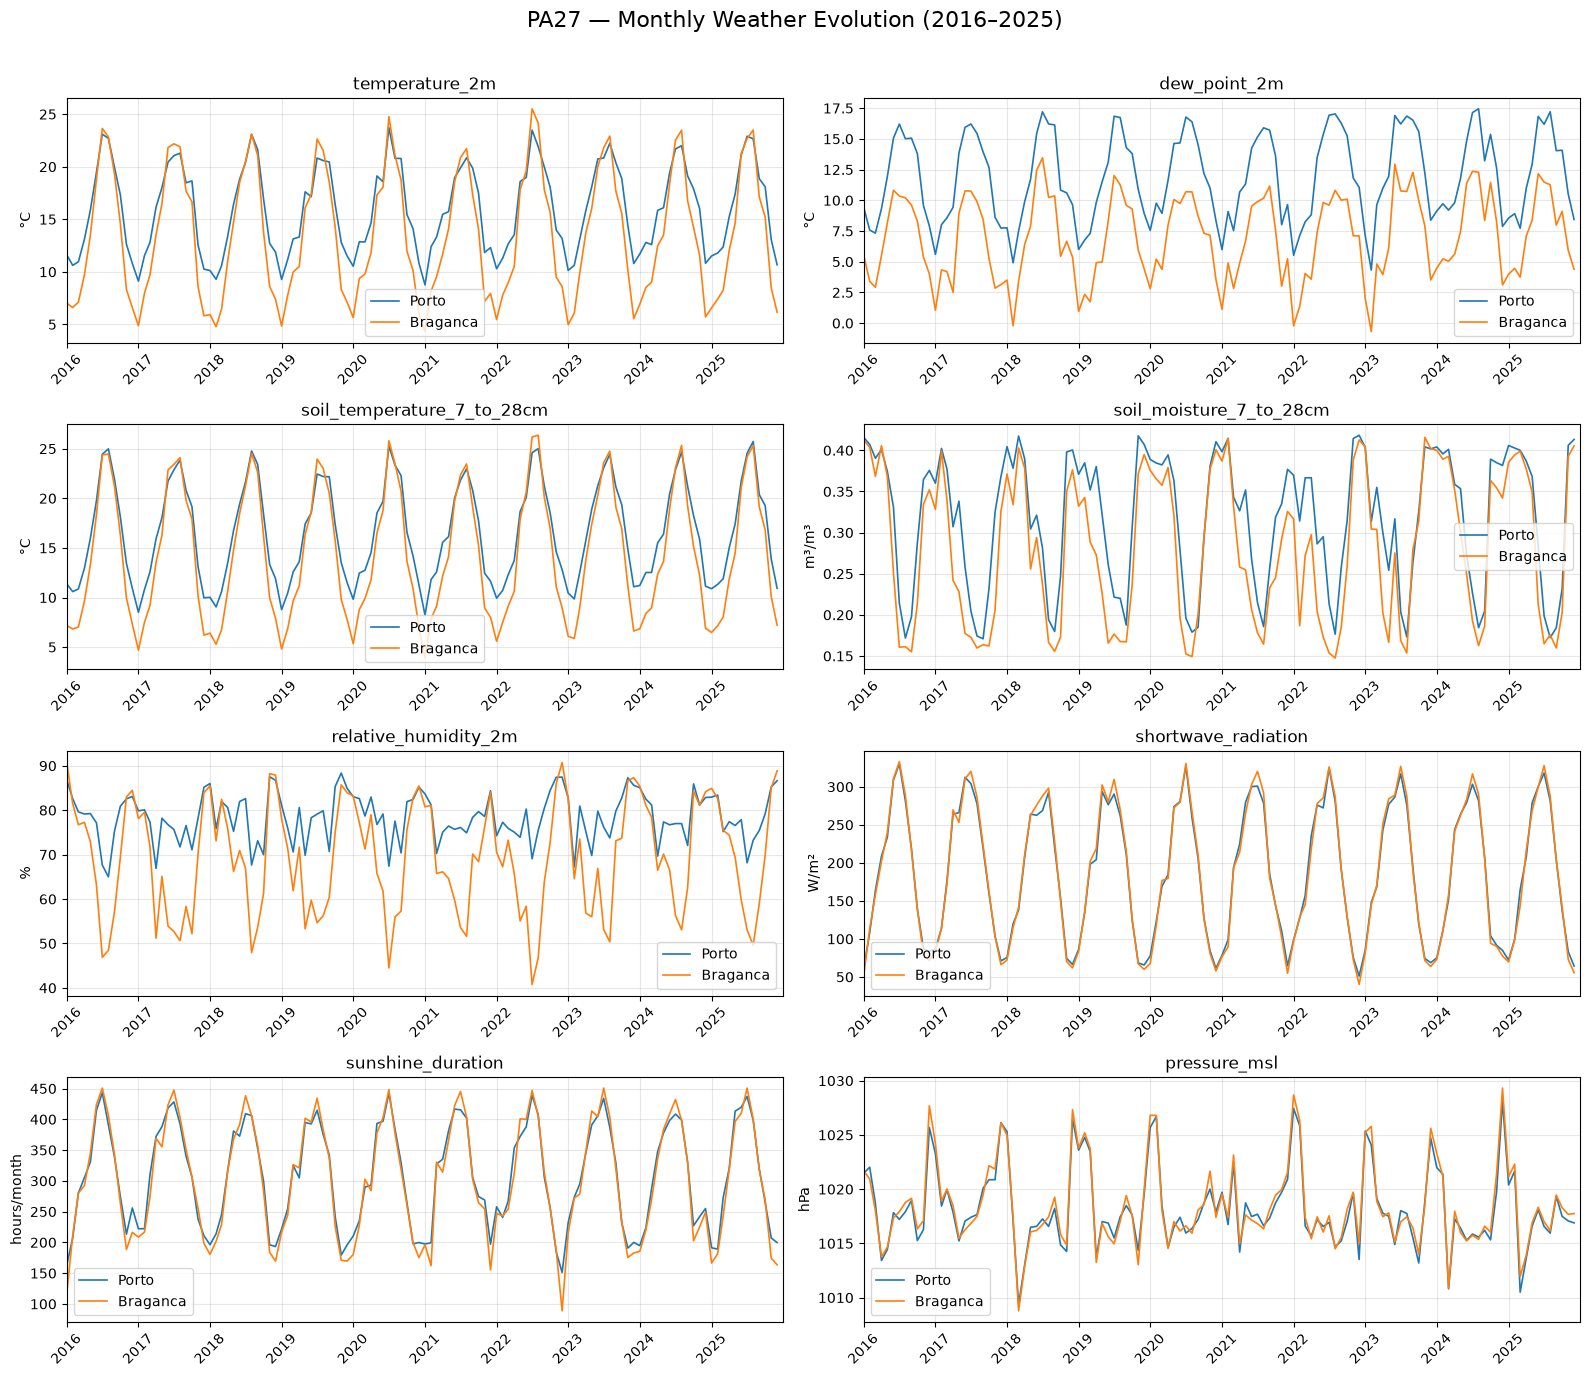

In [108]:
fig, axes = plt.subplots(
    4, 2,
    figsize=(16, 14),
    sharex=True
)

axes = axes.flatten()

for name, df in cities.items():

    monthly = (
        df.assign(
            timestamp_utc=pd.to_datetime(df["timestamp_utc"])
        )
        .set_index("timestamp_utc")[weather_global]
        .resample("MS")
        .agg(agg_methods)
    )

    monthly["sunshine_duration"] /= 3600

    for ax, var in zip(axes, weather_global):
        ax.plot(
            monthly.index,
            monthly[var],
            label=name,
            linewidth=1.2
        )

for ax, var in zip(axes, weather_global):
    ax.set_title(var)
    ax.set_ylabel(units[var])
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x", labelbottom=True, rotation=45)

    ax.set_xlim(
        pd.Timestamp("2016-01-01"),
        pd.Timestamp("2025-12-31")
    )

fig.suptitle(
    "PA27 — Monthly Weather Evolution (2016–2025)",
    fontsize=16
)

fig.tight_layout(rect=[0, 0, 1, 0.97])

fig.savefig(
    FIG_DIR / "03_weather_evolution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Bragança has bigger temperature variations, with hotter summers and colder winters, while Porto has milder temperatures and higher humidity. 

Soil moisture generally decreases during summer as temperatures and solar radiation increase. 

Sunshine duration and shortwave radiation follow similar seasonal patterns in both locations, reaching their highest values during summer.

Atmospheric pressure shows similar fluctuations in both regions, without a clear seasonal pattern.

Overall, the graphs highlight the differences between Porto’s maritime climate and Bragança’s more continental climate, with the most noticeable differences occurring in temperature, humidity, and soil moisture.

## 5. Target frequency and Class Distribution

We compare the frequency of Cold Stress events in Porto and Bragança, focusing on the differences in target distribution and potential class imbalance that may affect model performance.

,city,n_hours,cold_hours,non_cold_hours,cold_rate_pct
0,Porto,87672,7443,80229,8.49
1,Braganca,87672,25793,61879,29.42


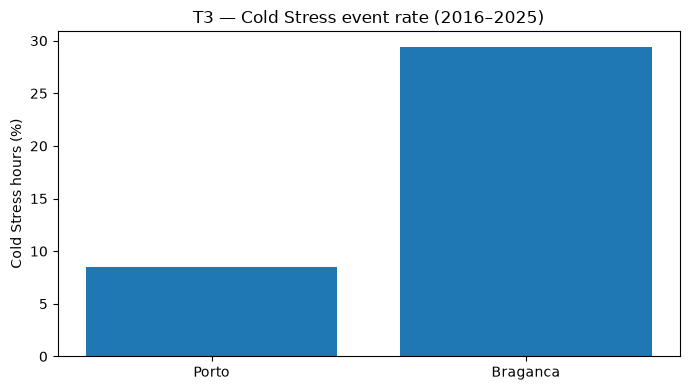

In [109]:
frequency = pd.DataFrame([
    {
        "city": name,
        "n_hours": len(df),
        "cold_hours": int(df[TARGET_COLUMN].sum()),
        "non_cold_hours": int((df[TARGET_COLUMN] == 0).sum()),
        "cold_rate_pct": df[TARGET_COLUMN].mean() * 100
    }
    for name, df in cities.items()
])

display(frequency.round(2))
frequency.to_csv(TAB_DIR / "04_target_frequency.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(frequency["city"], frequency["cold_rate_pct"])
ax.set_ylabel("Cold Stress hours (%)")
ax.set_title("T3 — Cold Stress event rate (2016–2025)")

fig.tight_layout()
fig.savefig(FIG_DIR / "04_target_frequency.png", dpi=150)
plt.show()

Cold Stress events are more than 3 times more frequent in Bragança (29.42%) than in Porto (8.49%). Both cities show class imbalance, particularly Porto, where Cold Stress represents a small minority of observations. 

## 6. Rolling/window behaviour

This shows how weather conditions and Cold Stress events change over time using rolling windows, helping identify temporal patterns, trends, and periods of increased Cold Stress.

**Note:** The 24-hour rolling rate measures the proportion of Cold Stress hours within each 24-hour window, including the current hour. These rates are then averaged weekly to make temporal patterns easier to visualize. For predictive features, only previous hours (up to t−1) would be used to avoid data leakage.

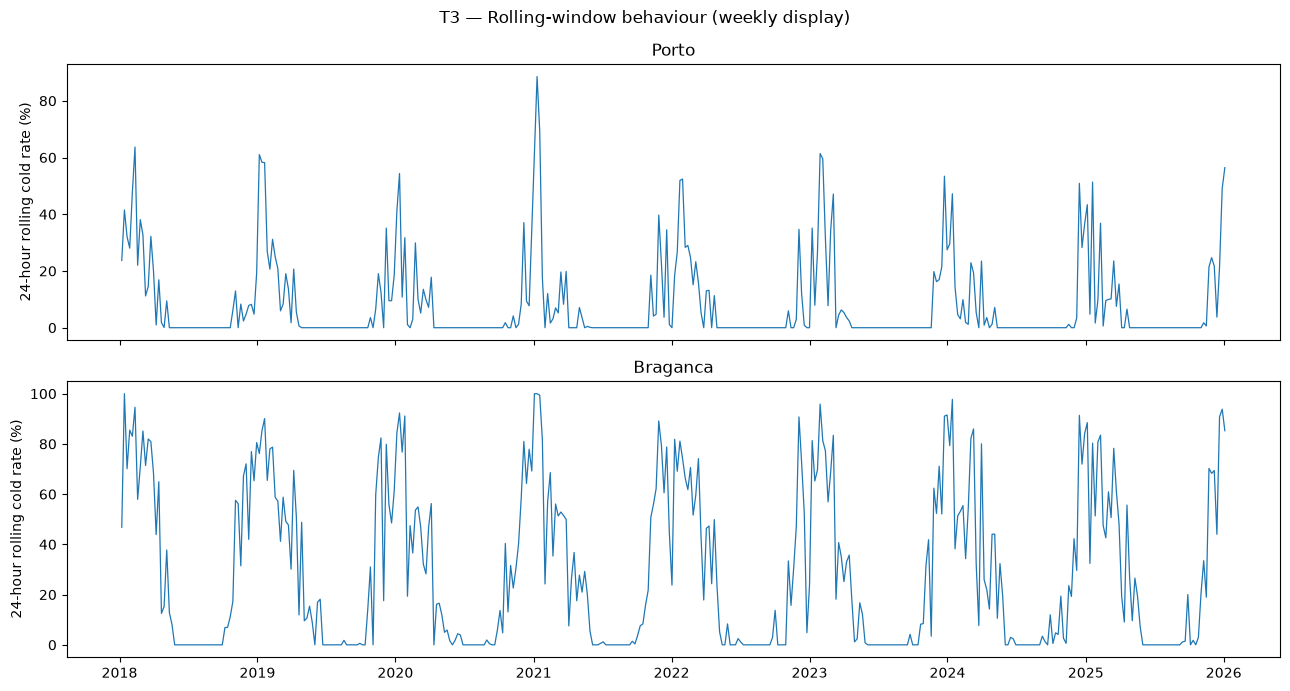

In [110]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
rolling_rows = []
for ax, (name, df) in zip(axes, evaluation.items()):
    rate = df[TARGET_COLUMN].rolling(window=24, min_periods=24).mean()
    # Agregação semanal da taxa móvel para o gráfico ficar legível.
    weekly_rate = pd.DataFrame({"timestamp": df["timestamp_utc"], "rate": rate}).set_index("timestamp")["rate"].resample("W").mean()
    ax.plot(weekly_rate.index, weekly_rate * 100, linewidth=0.9)
    ax.set_title(name)
    ax.set_ylabel("24-hour rolling cold rate (%)")
    rolling_rows.append(pd.DataFrame({"city": name, "timestamp_utc": weekly_rate.index, "rate_pct": weekly_rate.values * 100}))
fig.suptitle("T3 — Rolling-window behaviour (weekly display)")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_rolling_cold_rate.png", dpi=150)
plt.show()
pd.concat(rolling_rows).to_csv(TAB_DIR / "05_rolling_cold_rate.csv", index=False)

The rolling-window analysis shows a clear seasonal pattern, with Cold Stress events occurring mainly during winter and becoming rare in warmer months. Bragança experiences more frequent and sustained periods of Cold Stress, often reaching rates close to 100%, while Porto shows shorter and less frequent peaks.

## 7. Unusual / extreme observations

We will examine the distribution of selected weather variables in Porto and Bragança using boxplots to identify extreme values, potential outliers, and differences between the two cities.

In [111]:
extreme_rows = []

feature_sets = {
    "Porto-specific": {
        "Porto": weather_porto + ["relative_humidity_2m"]
    },
    "Braganca-specific": {
        "Braganca": weather_braganca
    }
}

for feature_set, city_features in feature_sets.items():

    for city, variables in city_features.items():

        df = cities[city]

        for var in variables:
            low, high = df[var].quantile([0.01, 0.99])

            extreme_rows.append({
                "feature_set": feature_set,
                "city": city,
                "variable": var,
                "min": df[var].min(),
                "p01": low,
                "p99": high,
                "max": df[var].max(),
                "below_p01": int((df[var] < low).sum()),
                "above_p99": int((df[var] > high).sum())
            })

extremes = pd.DataFrame(extreme_rows)

# Display results by feature set
for feature_set in feature_sets:
    print(f"\n{feature_set}")
    display(
        extremes[
            extremes["feature_set"] == feature_set
        ].round(2)
    )

# Export all results
extremes.to_csv(
    TAB_DIR / "06_extreme_values.csv",
    index=False
)


Porto-specific


,feature_set,city,variable,min,p01,p99,max,below_p01,above_p99
0,Porto-specific,Porto,temperature_2m,0.40,4.60,29.60,37.00,865,835
1,Porto-specific,Porto,dew_point_2m,-4.60,1.20,19.80,23.50,836,825
2,Porto-specific,Porto,soil_temperature_7_to_28cm,4.10,7.30,27.20,29.90,857,814
3,Porto-specific,Porto,soil_moisture_7_to_28cm,0.15,0.17,0.43,0.43,731,667
4,Porto-specific,Porto,sunshine_duration,0.00,0.00,3600.00,3600.00,0,0
5,Porto-specific,Porto,vapour_pressure_deficit,0.00,0.02,2.31,4.51,425,870
6,Porto-specific,Porto,shortwave_radiation,0.00,0.00,925.00,999.00,0,876
7,Porto-specific,Porto,wind_direction_10m,1.00,5.00,358.00,360.00,755,736
8,Porto-specific,Porto,pressure_msl,977.40,998.50,1033.70,1039.50,869,863
9,Porto-specific,Porto,relative_humidity_2m,18.00,38.00,98.00,100.00,732,616



Braganca-specific


,feature_set,city,variable,min,p01,p99,max,below_p01,above_p99
10,Braganca-specific,Braganca,temperature_2m,-4.80,-0.80,32.30,40.60,867,866
11,Braganca-specific,Braganca,dew_point_2m,-15.70,-5.20,15.80,19.10,835,823
12,Braganca-specific,Braganca,soil_temperature_7_to_28cm,0.90,3.00,27.90,31.90,855,819
13,Braganca-specific,Braganca,soil_moisture_7_to_28cm,0.13,0.14,0.43,0.45,800,798
14,Braganca-specific,Braganca,relative_humidity_2m,9.00,22.00,99.00,100.00,840,497
15,Braganca-specific,Braganca,shortwave_radiation,0.00,0.00,936.00,1006.00,0,864
16,Braganca-specific,Braganca,sunshine_duration,0.00,0.00,3600.00,3600.00,0,0
17,Braganca-specific,Braganca,pressure_msl,977.60,998.80,1034.90,1042.10,872,864
18,Braganca-specific,Braganca,cloud_cover_low,0.00,0.00,100.00,100.00,0,0
19,Braganca-specific,Braganca,cloud_cover,0.00,0.00,100.00,100.00,0,0


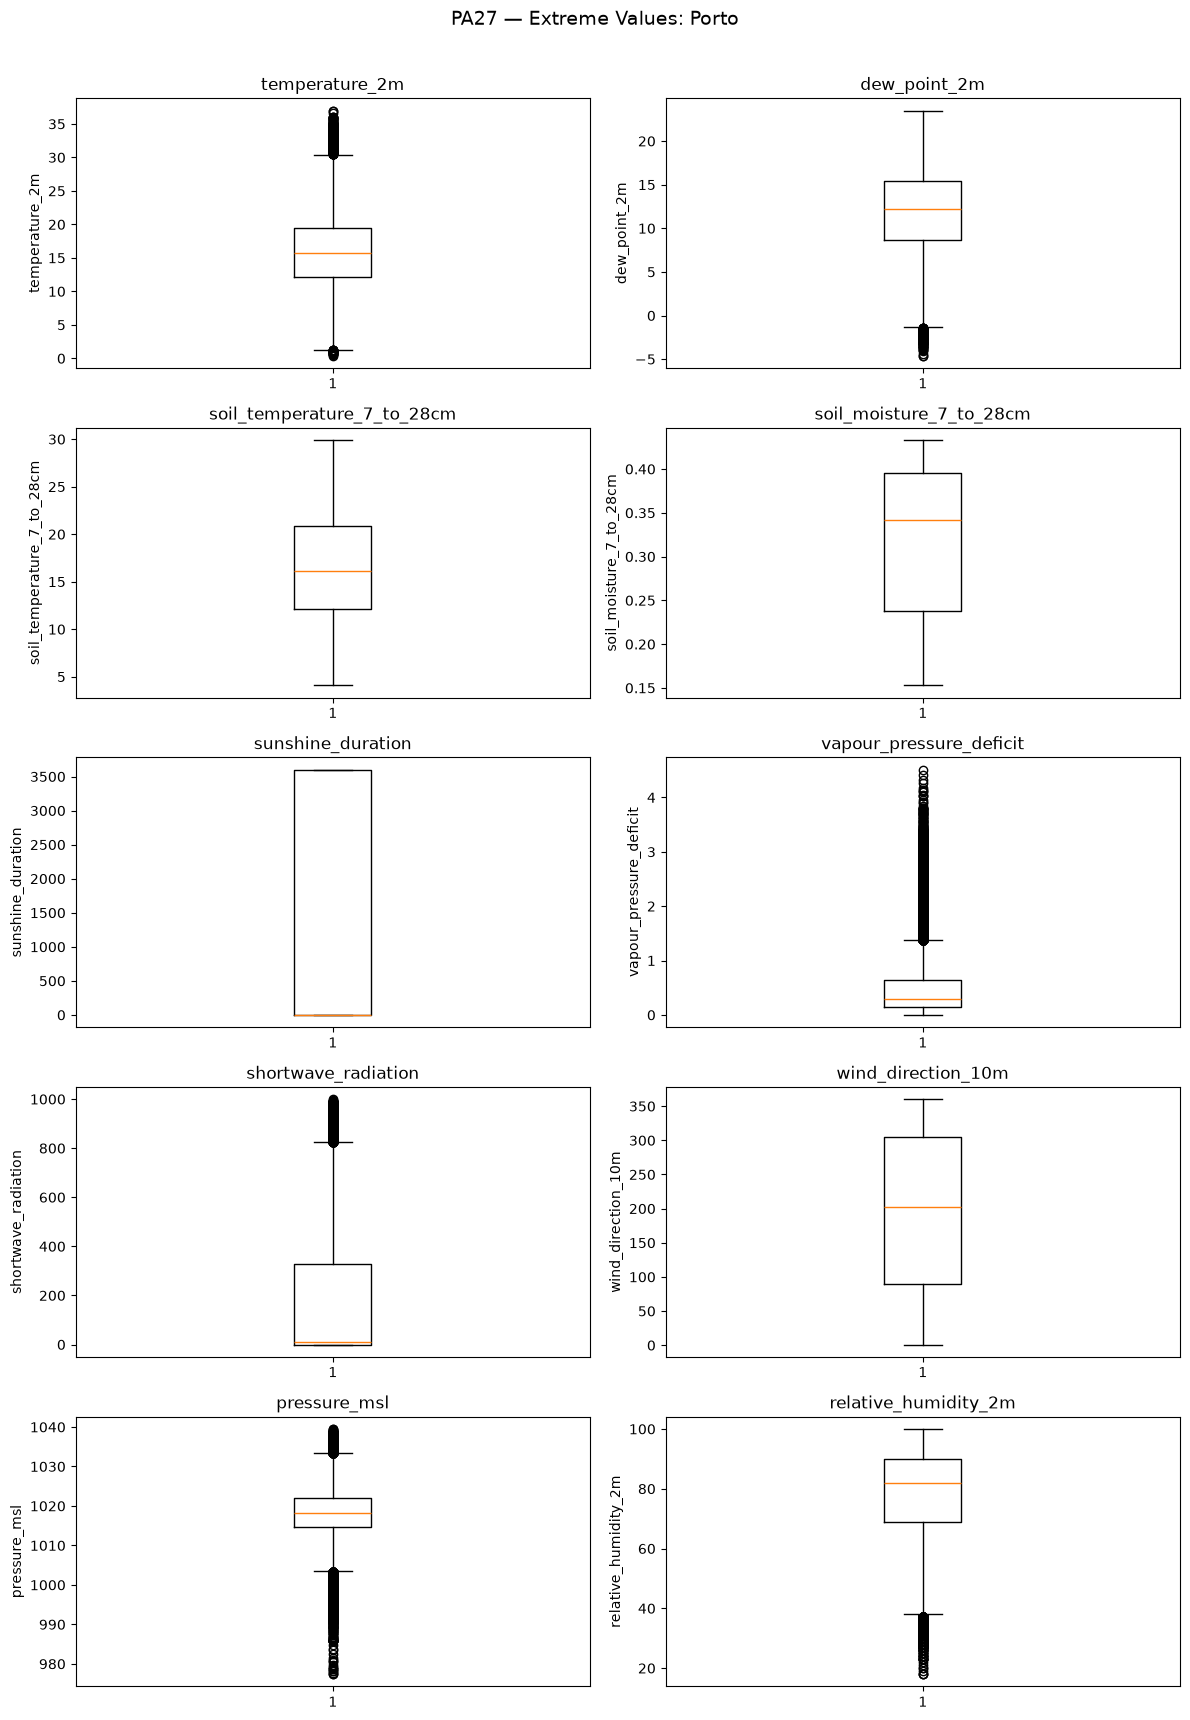

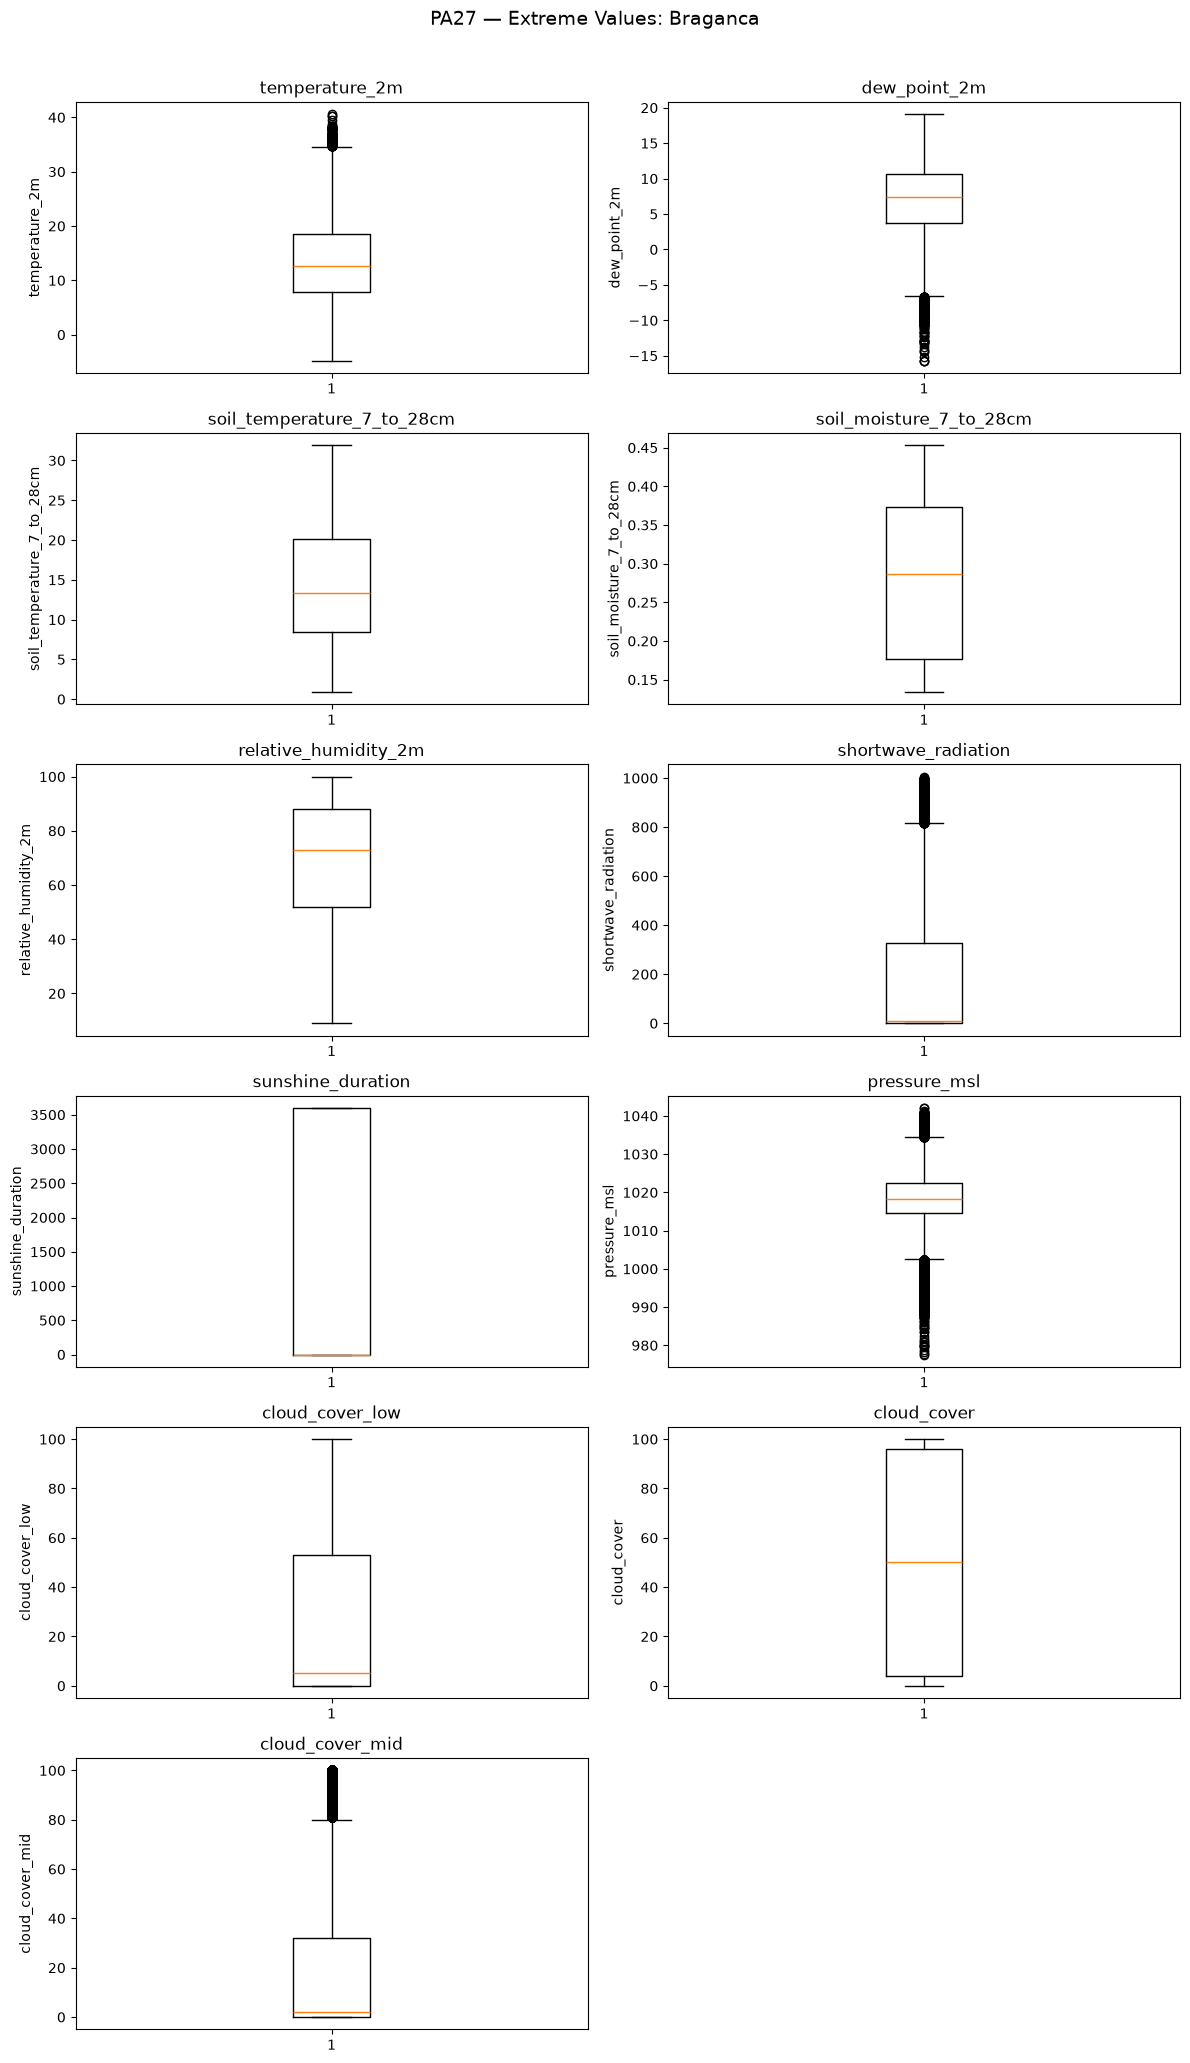

In [112]:
for feature_set, city_features in feature_sets.items():
    for city, variables in city_features.items():

        df = cities[city]
        variables = list(dict.fromkeys(variables))

        n_rows = (len(variables) + 1) // 2

        fig, axes = plt.subplots(
            n_rows, 2,
            figsize=(12, 3.5 * n_rows),
            squeeze=False
        )

        for ax, var in zip(axes.flatten(), variables):

            ax.boxplot(
                df[var].dropna(),
                orientation="vertical",
                showfliers=True
            )

            ax.set_title(var)
            ax.set_ylabel(var)

        # Hide unused subplots
        for ax in axes.flatten()[len(variables):]:
            ax.axis("off")

        fig.suptitle(
            f"PA27 — Extreme Values: {city}",
            fontsize=14
        )

        fig.tight_layout(rect=[0, 0, 1, 0.97])

        fig.savefig(
            FIG_DIR / f"06_extreme_boxplots_{city.lower()}.png",
            dpi=150,
            bbox_inches="tight"
        )

        plt.show()


The boxplots reveal several extreme observations, particularly in temperature, dew point, atmospheric pressure, and solar radiation.

Bragança shows greater temperature variability and lower minimum temperatures than Porto, consistent with its higher Cold Stress frequency. 

These extreme values reflect genuine weather conditions rather than data errors, so we will not be removing them yet.

## 8. Business Context

According to the Federal Highway Administration (FHWA, 2016), weather conditions play an important role in winter road maintenance, influencing decisions related to personnel, equipment, and preventive treatments. Our goal in this final section is to analyze the monthly frequency and duration of Cold Stress events in Porto and Bragança, which helps to identify periods of increased cold conditions and understand their potential impact on road-service planning.

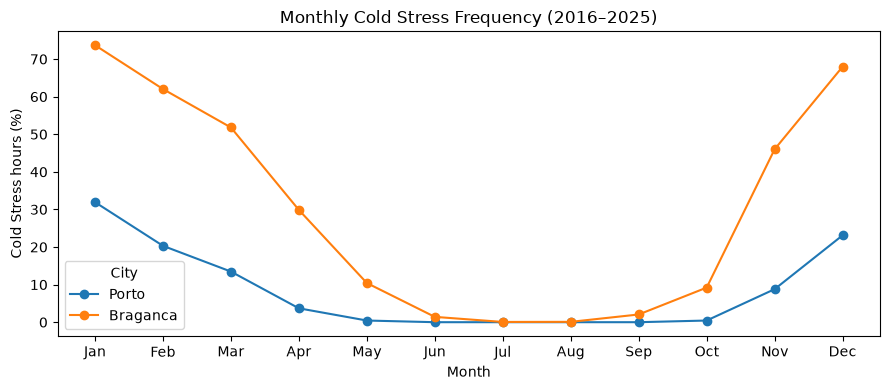

In [113]:
fig, ax = plt.subplots(figsize=(9, 4))
monthly_rows = []

for name, df in cities.items():
    profile = df.groupby(df["timestamp_utc"].dt.month)[TARGET_COLUMN].mean() * 100

    ax.plot(profile.index, profile.values, marker="o", label=name)

    monthly_rows.append(pd.DataFrame({
        "city": name,
        "month": profile.index,
        "cold_rate_pct": profile.values
    }))

ax.set_xticks(range(1, 13))
ax.set_xticklabels([
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
])

ax.set_xlabel("Month")
ax.set_ylabel("Cold Stress hours (%)")
ax.set_title("Monthly Cold Stress Frequency (2016–2025)")
ax.legend(title="City")

fig.tight_layout()
fig.savefig(FIG_DIR / "07_monthly_cold_profile.png", dpi=150)
plt.show()

pd.concat(monthly_rows).to_csv(
    TAB_DIR / "07_monthly_cold_profile.csv",
    index=False
)


In [114]:
def cold_spell_lengths(series):
    runs = series.ne(series.shift()).cumsum()
    return series.groupby(runs).agg(["first", "size"]).query("first == 1")["size"]

spell_tables = []

for name, df in cities.items():
    # Ensure chronological order
    df = df.sort_values("timestamp_utc")

    lengths = cold_spell_lengths(df[TARGET_COLUMN])

    spell_tables.append({
        "city": name,
        "number_of_spells": len(lengths),
        "mean_duration_hours": lengths.mean(),
        "median_duration_hours": lengths.median(),
        "max_duration_hours": lengths.max(),
        "spells_24h_or_longer": int((lengths >= 24).sum())
    })

spell_summary = pd.DataFrame(spell_tables)

display(spell_summary.round(2))

spell_summary.to_csv(
    TAB_DIR / "07_cold_spell_duration.csv",
    index=False
)


,city,number_of_spells,mean_duration_hours,median_duration_hours,max_duration_hours,spells_24h_or_longer
0,Porto,787,9.46,9.0,46,4
1,Braganca,1605,16.07,13.0,526,145



| Column | Description |
|---|---|
| `number_of_spells` | Total number of Cold Stress episodes. |
| `mean_duration_hours` | Average duration of Cold Stress episodes, in hours. |
| `median_duration_hours` | Median duration of Cold Stress episodes, in hours. |
| `max_duration_hours` | Duration of the longest Cold Stress episode, in hours. |
| `spells_24h_or_longer` | Number of episodes lasting at least 24 consecutive hours. |


Cold Stress follows a clear seasonal pattern, with the highest frequencies occurring during winter, especially in Bragança. 

Between 2016 and 2025, Bragança recorded more frequent and longer Cold Stress episodes (1,605 events, averaging 16.07 hours) than Porto (787 events, averaging 9.46 hours). Bragança also experienced substantially more prolonged events lasting at least 24 hours (145 compared with 4 in Porto). 

Therefore, in the business context, it's possible to conclude that Bragança needs a greater sustained monitoring and winter road maintenance planning.